# 02 — Cluster launch overhead, cluster occupancy and placement on the H100 NVL

**Goal.** A thread-block cluster gives a group of CTAs a shared, distributed shared memory and a hardware barrier, but the hardware must place all CTAs of a cluster on SMs of one GPC at the same time. This experiment measures what that constraint costs on this GPU, before any distributed-shared-memory traffic is involved:

1. how much longer a kernel takes when it is launched as clusters of 1, 2, 4, 8 or 16 CTAs instead of as plain CTAs, with the same grid and block;
2. how many clusters of each size are resident at once, and how many SMs stay idle;
3. how the three cluster scheduling policies (Default, Spread, LoadBalancing) place the CTAs of a cluster on physical SMs, and whether that placement repeats from launch to launch.

These numbers are the fixed cost under every cluster-based algorithm, and the placement records are the raw material for mapping SMs to GPCs.

## Background

**Clusters.** A kernel launched with a cluster dimension groups its CTAs into clusters of `CS` CTAs (here 1-D: CTAs `c·CS … c·CS+CS−1` form cluster `c`). The CTAs of a cluster are guaranteed to run at the same time on SMs of one *GPC* (graphics processing cluster, a group of up to 9 TPCs = 18 SMs that shares the SM-to-SM network). The hardware launches a cluster only when it can place **all** of its CTAs at once. Portable cluster sizes go up to 8; 16 needs `cudaFuncAttributeNonPortableClusterSizeAllowed`. Inside the kernel a CTA can read where it runs:

```
mov.u32 %r, %smid;              // physical SM (S2R SR_VIRTUALSMID)
mov.u32 %r, %clusterid.x;       // cluster index in the grid
mov.u32 %r, %cluster_ctarank;   // rank of this CTA in its cluster (S2R SR_CgaCtaId)
mov.pred %p, %is_explicit_cluster;
```

**Launching.** The same kernel is launched through `cudaLaunchKernelEx` either without attributes or with
```cpp
attrs[0].id = cudaLaunchAttributeClusterDimension;                  attrs[0].val.clusterDim = {CS, 1, 1};
attrs[1].id = cudaLaunchAttributeClusterSchedulingPolicyPreference; attrs[1].val.clusterSchedulingPolicyPreference = policy;
```
A cluster dimension of 1 still makes an *explicit* cluster launch (`%is_explicit_cluster` = 1), which is the closest comparison to a plain launch.

**Scheduling policies.** `cudaClusterSchedulingPolicyDefault`, `…Spread` ("spread the blocks within a cluster to the SMs") and `…LoadBalancing` ("allow the hardware to load-balance the blocks in a cluster to the SMs"). Only LoadBalancing is allowed to put two CTAs of the same cluster on one SM.

**Occupancy.** `cudaOccupancyMaxActiveClusters` predicts how many clusters of a configuration fit on the GPU at once. With one CTA per SM, a GPC with `n` usable SMs can hold at most ⌊n / CS⌋ clusters, so SMs are lost to fragmentation whenever GPC sizes are not multiples of the cluster size. A kernel whose grid needs more clusters than fit runs in *waves*, and a cluster launch can need more waves than a plain launch of the same grid. That is the main source of cluster launch overhead examined here.

## Experimental setup

**Device and configuration.** NVIDIA H100 NVL, 132 SMs, 60 MiB L2, HBM3 at 2619 MHz; power limit 400 W, ECC on, MIG off; driver 580.126.20, CUDA 12.9 (`nvcc -arch=sm_90a -O3`). The SM clock is locked at 1635 MHz with `nvidia-smi -lgc`. Every recorded launch is followed by an NVML sample of the SM and memory clocks and the throttle reasons; a launch is flagged if a throttle reason is set or the SM clock reads more than 15 MHz below the lock (the table below gives the count).

**Kernel.** `sleep_kernel(rec, cycles)`: 1024 threads per CTA. Thread 0 reads `%globaltimer` on entry, every thread spins on `%clock64` until `cycles` SM cycles have elapsed, the CTA synchronises, and thread 0 reads `%globaltimer` again and stores `{block, %smid, %clusterid.x, %cluster_ctarank, %cluster_nctarank, %is_explicit_cluster, t_start, t_end}`. The spin loop in SASS:
```
CS2R R6, SR_CLOCKLO ;  IADD3 R0, P0, -R4, R6, RZ ;  IMAD.X R6, R7, 0x1, ~R5, P0 ;
ISETP.GE.U32.AND P0, PT, R0, UR4, PT ;  ISETP.GE.U32.AND.EX P0, PT, R6, UR5, PT, P0 ;  @!P0 BRA
```
Dynamic shared memory of 0, 64 KB or 200 KB is allocated but not used: it only sets how many CTAs fit on an SM. At 1024 threads at most 2 CTAs share an SM (2048 threads per SM), so 0 and 64 KB both allow 2 CTAs/SM; 200 KB allows exactly 1. The host checks every record (all CTAs wrote, `clusterid = block / CS`, `rank = block % CS`, `nctarank = CS`, `is_explicit_cluster` = 1 exactly for cluster launches).

| Probe | Configurations | Repetitions | Timer |
|---|---|---|---|
| K1 launch overhead | `cycles` = 100 000 (≈ 61 µs). No cluster, and clusters of 1, 2, 4, 8, 16 (policy Default). Grid targets 1, 8, 16, 32, 64, 128, 132, 264, 528, 1056, 2112 CTAs, rounded up to a multiple of CS; the no-cluster kernel also runs at every rounded grid so that each cluster launch has a no-cluster launch with the identical grid. Shared memory 0 / 64 KB / 200 KB | 2 warm-ups per configuration, then 5 repetitions; one repetition launches every configuration of a grid target once, no cluster first | one `cudaEvent` pair around each launch |
| Event floor | 1000 event pairs with nothing between them; 200 launches of an empty 1024-thread kernel per cluster size (grid = CS) | — | `cudaEvent` pairs |
| K2 occupancy | `cycles` = 2 000 000 (≈ 1.2 ms, so that all co-resident CTAs overlap). CS 2, 4, 8, 16 × Default / Spread / LoadBalancing × 0 / 64 KB / 200 KB × grid = 1× and 4× `cudaOccupancyMaxActiveClusters` · CS | 2 warm-ups, then 5 consecutive repetitions | `%globaltimer` per CTA |
| Nsight Compute | one launch per K2 configuration (1×) and the K1 configurations at 2112 CTAs / 200 KB; launch statistics and `gpc__cgas_*` counters, `--clock-control none` | 1 | ncu |
| Nsight Systems | 20 back-to-back launches per configuration at 2112 CTAs / 200 KB, no synchronisation between them | 20 | nsys GPU trace |

**Definitions.** *Overhead* of a cluster launch = (T_cluster − T_floor) / (T_no-cluster − T_floor) − 1, where T_no-cluster is the plain launch with the same grid in the same repetition and T_floor is the median of the empty event pairs. *First wave* = the clusters all of whose CTAs started before the earliest CTA ended; *SMs used* = distinct `%smid` of first-wave CTAs; *idle SMs* = 132 − SMs used.

In [1]:
%matplotlib inline
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown

R = "results"
EXP = "02__cluster_launch_and_occupancy"
F = f"{R}/02__cluster_launch__"
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#a35bd0", "#d4a20c", "#d6457a", "#4fb3c8", "#7a6e5c"]
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "figure.dpi": 110,
})
pd.set_option("display.precision", 3)
SMEM = {0: "0 KB (2 CTAs/SM)", 65536: "64 KB (2 CTAs/SM)", 204800: "200 KB (1 CTA/SM)"}
CS_COL = {0: INK2, 1: PAL[6], 2: PAL[0], 4: PAL[1], 8: PAL[2], 16: PAL[3]}

def q(s, p): return np.percentile(s, p)
def summary(s):
    s = pd.Series(s).astype(float)
    return pd.Series({"median": s.median(), "mean": s.mean(), "std": s.std(), "p5": q(s, 5), "p95": q(s, 95), "n": len(s)})

runs = pd.read_csv(f"{R}/{EXP}__runs.csv")
status = runs.groupby("run_id")["status"].agg(lambda s: "complete" if "complete" in set(s) else "partial")
cmd = runs.dropna(subset=["started_iso"]).set_index("run_id")["cmdline"]
clog = pd.read_csv(f"{R}/{EXP}__clock_log.csv")

def latest_complete(df, sub):
    ids = [r for r in df["run_id"].unique() if status.get(r) == "complete" and re.search(rf"cluster_launch {sub}(\s|$)", cmd.get(r, ""))]
    rid = max(ids)
    return df[df["run_id"] == rid].copy(), rid

In [2]:
first = clog.iloc[0]
dev = pd.DataFrame({
    "GPU": [first.gpu_name], "SMs": [first.sm_count], "CUDA runtime": [first.cuda_version], "driver": [first.driver_version],
    "locked SM clock (requested)": [f"{int(clog.lock_sm_mhz.max())} MHz"],
    "SM clock reported by NVML (min–max over all samples)": [f"{clog.sm_clock_mhz.min()}–{clog.sm_clock_mhz.max()} MHz"],
    "memory clock (NVML)": [f"{clog.mem_clock_mhz.min()}–{clog.mem_clock_mhz.max()} MHz"],
    "board power (min–max)": [f"{clog.power_w.min():.0f}–{clog.power_w.max():.0f} W"],
    "GPU / HBM temperature max": [f"{clog.gpu_temp_c.max()} / {clog.mem_temp_c.max()} °C"],
})
display(dev.T.rename(columns={0: ""}))

r = runs.dropna(subset=["started_iso"])[["run_id", "cmdline"]].copy()
r["mode"] = r.cmdline.str.extract(r"cluster_launch (\w+)")[0]
r["status"] = r.run_id.map(status)
display(r[["run_id", "mode", "status"]].reset_index(drop=True))

ovh, rid_k1 = latest_complete(pd.read_csv(F + "overhead.csv"), "overhead")
occ, rid_k2 = latest_complete(pd.read_csv(F + "occupancy.csv"), "occupancy")
flr = pd.read_csv(F + "floor.csv"); flr = flr[flr.run_id == rid_k1]
flag = clog[(clog.phase == "launch") & ((clog.throttle == 1) | (clog.below_lock == 1))]
print(f"recorded launches: K1 {len(ovh)}, K2 {len(occ)}; launches flagged by the clock sample: {len(flag)}; "
      f"K1/K2 rows with clock_ok = 0: {(ovh.clock_ok == 0).sum()} / {(occ.clock_ok == 0).sum()} (none discarded)")

,
GPU,NVIDIA H100 NVL
SMs,132
CUDA runtime,12.9
driver,580.126.20
locked SM clock (requested),1635 MHz
SM clock reported by NVML (min–max over all samples),1635–1635 MHz
memory clock (NVML),2619–2619 MHz
board power (min–max),89–129 W
GPU / HBM temperature max,34 / 37 °C


,run_id,mode,status
0,2026-10-23T22:59:03.688+00:00,clockcheck,complete
1,2026-10-23T22:59:04.539+00:00,overhead,complete
2,2026-10-23T22:59:12.029+00:00,occupancy,complete
3,2026-10-23T22:59:19.377+00:00,ncu,complete
4,2026-10-23T22:59:29.332+00:00,nsys,complete
5,2026-10-23T22:59:32.522+00:00,clockcheck,complete


recorded launches: K1 1110, K2 360; launches flagged by the clock sample: 0; K1/K2 rows with clock_ok = 0: 0 / 0 (none discarded)


## Results

### K1 — launch overhead versus grid size

Overhead is zero (within ±2 %) until the grid needs more waves as clusters than as plain CTAs, and then jumps by the ratio of the wave counts. Clusters of 1 and 2 never lose SMs and never pay. With 1 CTA/SM a wave holds 132 plain CTAs but only 120 CTAs in clusters of 4 or 8 and 112 in clusters of 16, so a 128-CTA grid (and a 132-CTA grid in clusters of 4) needs a second wave: +90 %. Grids that are rounded up to 136, 144 or 272 CTAs need the same number of waves in both forms and pay nothing. With 2 CTAs/SM (264 plain CTAs per wave vs. 248, 240 and 224) the same step appears at 264 CTAs. At 2112 CTAs the overhead settles at about +12 % for clusters of 4 and 8 and +19 % (1 CTA/SM) or +24 % (2 CTAs/SM) for clusters of 16: the ratio of the wave counts.

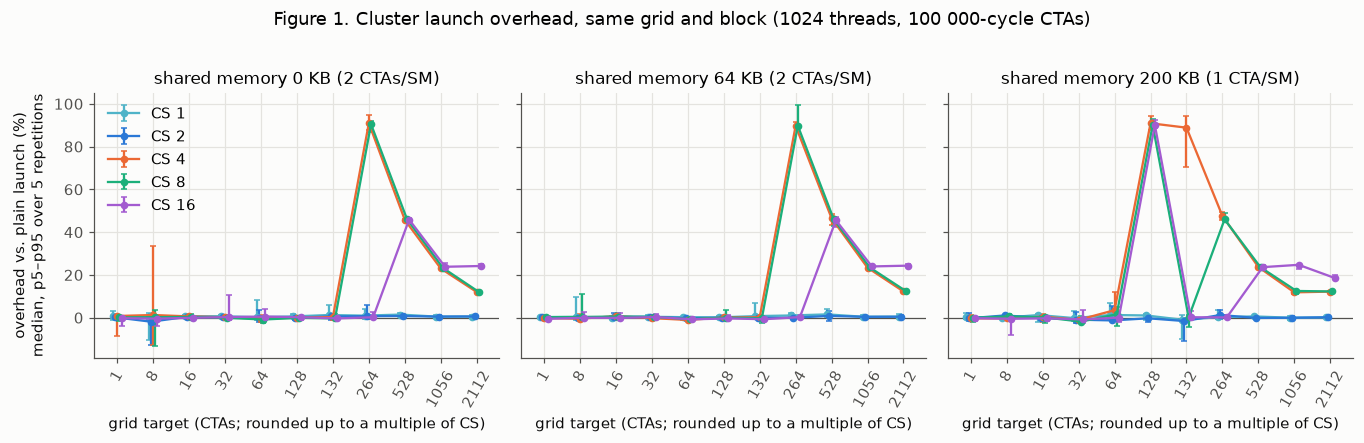

**Median overhead (%)**

grid_target    1     8     16    32    64    128   132   264   528   1056  \
smem_bytes cs                                                               
0          1    0.8  -0.0   0.6   0.7   0.2   0.6   1.2   1.0   1.5   0.5   
           2    0.2  -1.9   0.4   0.2  -0.2   0.0   0.6   0.7   0.8   0.5   
           4    0.8   1.3   0.6   0.2  -0.5   0.0   0.3  90.9  45.7  23.0   
           8    0.1   0.3   0.3  -0.0  -0.9  -0.0  -0.3  90.5  46.1  23.3   
           16  -0.2  -0.4  -0.0   0.3   0.5   0.2  -0.3   0.2  45.9  23.8   
65536      1    0.3   0.3   0.0   0.4   0.2   0.1   0.7   1.0   1.5   0.4   
           2    0.3  -0.3   0.5   0.4  -0.2   0.0  -0.1  -0.0   0.9   0.4   
           4   -0.1  -0.4   0.7  -0.2  -1.1   0.1   0.2  89.7  46.5  23.4   
           8    0.2   0.3   0.5   0.3  -0.7   0.0  -0.3  89.8  46.0  23.5   
           16  -0.5  -0.0  -0.1   0.3  -0.8  -0.3  -0.7   0.3  45.6  24.0   
204800     1    0.4  -0.0   1.2  -0.2   1.3   1.0  -1.0   0.2   0.6   0.0   
           2   -0.3   1.0   0.0  -0.9  -1.3  -0.3  -1.6   1.2  -0.1  -0.0   
           4   -0.3  -0.3   0.5  -1.0   3.5  90.9  88.8  47.6  23.7  11.8   
           8   -0.0   0.6   0.1  -1.8   1.6  90.1   0.1  46.0  23.5  12.5   
           16  -0.2  -0.5  -0.3  -0.8   0.0  90.1   0.2   0.1  23.6  24.7   

grid_target    2112  
smem_bytes cs        
0          1    0.5  
           2    0.6  
           4   12.0  
           8   12.0  
           16  24.2  
65536      1    0.5  
           2    0.4  
           4   12.3  
           8   12.5  
           16  24.3  
204800     1    0.1  
           2    0.2  
           4   12.2  
           8   12.3  
           16  18.6

In [3]:
c = ovh[ovh.cs > 0]
targets = sorted(c.grid_target.unique()); xpos = {g: i for i, g in enumerate(targets)}
fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.9), sharey=True)
for ax, smem in zip(axs, [0, 65536, 204800]):
    for j, cs in enumerate([1, 2, 4, 8, 16]):
        g = c[(c.smem_bytes == smem) & (c.cs == cs)].groupby("grid_target").overhead_pct
        m, lo, hi = g.median(), g.quantile(0.05), g.quantile(0.95)
        x = np.array([xpos[t] for t in m.index]) + (j - 2) * 0.06
        ax.errorbar(x, m.values, yerr=[m - lo, hi - m], color=CS_COL[cs], marker="o", ms=4, lw=1.5, capsize=2, label=f"CS {cs}")
    ax.set_xticks(range(len(targets)), [str(t) for t in targets], rotation=60)
    ax.set_xlabel("grid target (CTAs; rounded up to a multiple of CS)"); ax.set_title(f"shared memory {SMEM[smem]}")
    ax.axhline(0, color=INK2, lw=0.8)
axs[0].set_ylabel("overhead vs. plain launch (%)\nmedian, p5–p95 over 5 repetitions")
axs[0].legend(frameon=False, ncol=1)
fig.suptitle("Figure 1. Cluster launch overhead, same grid and block (1024 threads, 100 000-cycle CTAs)", y=1.02)
fig.tight_layout(); plt.show()

tab = c.groupby(["smem_bytes", "cs", "grid_target"]).overhead_pct.median().unstack("grid_target")
display(Markdown("**Median overhead (%)**")); display(tab.round(1))

In [4]:
# Time per wave: waves = ceil(grid / CTAs per wave predicted by the occupancy API), event time minus floor
w = ovh.copy()
w["waves"] = np.ceil(w.grid_blocks / w.api_blocks_per_wave)
w["us_per_wave"] = (w.ms_event - w.ms_floor) * 1e3 / w.waves
big = w[w.grid_target == 2112].groupby(["smem_bytes", "cs"]).agg(
    CTAs_per_wave=("api_blocks_per_wave", "first"), waves=("waves", "first"), grid=("grid_blocks", "first"),
    ms_event_median=("ms_event", "median"), us_per_wave_median=("us_per_wave", "median"), overhead_pct_median=("overhead_pct", "median"))
display(Markdown("**2112-CTA grid: CTAs per wave, waves and time per wave** (CS 0 = plain launch)")); display(big.round(3))
allw = w[w.waves >= 2].groupby("cs").us_per_wave.apply(summary).unstack()
display(Markdown("**Time per wave over all launches with ≥ 2 waves (µs)**")); display(allw[["median", "p5", "p95", "n"]].round(2))

**2112-CTA grid: CTAs per wave, waves and time per wave** (CS 0 = plain launch)

CTAs_per_wave  waves  grid  ms_event_median  \
smem_bytes cs                                                
0          0             264    8.0  2112            0.510   
           1             264    8.0  2112            0.513   
           2             264    8.0  2112            0.514   
           4             248    9.0  2112            0.570   
           8             240    9.0  2112            0.571   
           16            224   10.0  2112            0.632   
65536      0             264    8.0  2112            0.508   
           1             264    8.0  2112            0.509   
           2             264    8.0  2112            0.512   
           4             248    9.0  2112            0.570   
           8             240    9.0  2112            0.571   
           16            224   10.0  2112            0.632   
204800     0             132   16.0  2112            1.000   
           1             132   16.0  2112            0.999   
           2             132   16.0  2112            1.001   
           4             120   18.0  2112            1.120   
           8             120   18.0  2112            1.119   
           16            112   19.0  2112            1.182   

               us_per_wave_median  overhead_pct_median  
smem_bytes cs                                           
0          0               63.468                0.000  
           1               63.768                0.527  
           2               63.884                0.583  
           4               63.054               12.010  
           8               63.136               12.019  
           16              62.989               24.166  
65536      0               63.124                0.000  
           1               63.280                0.503  
           2               63.664                0.442  
           4               63.076               12.268  
           8               63.125               12.502  
           16              62.902               24.327  
204800     0               62.338                0.000  
           1               62.302                0.112  
           2               62.408                0.200  
           4               62.068               12.194  
           8               62.030               12.254  
           16              62.075               18.589

**Time per wave over all launches with ≥ 2 waves (µs)**

,median,p5,p95,n
cs,,,,
0,63.76,62.36,65.74,75.0
1,64.08,62.33,67.05,50.0
2,63.96,62.44,67.25,50.0
4,63.40,62.17,64.55,70.0
8,63.35,62.21,64.30,70.0
16,63.44,62.15,64.46,70.0


The time per wave is the same for every cluster size (≈ 62–64 µs for a 61 µs CTA), so on this GPU a cluster launch does not slow down the dispatch of each wave: the whole overhead of Figure 1 is the extra waves caused by idle SMs. The empty-kernel launches and the back-to-back trace below confirm that the fixed per-launch cost is the same with and without clusters.

### Fixed launch cost

In [5]:
fl = flr.copy(); fl["cs"] = fl.cs.fillna(-1).astype(int)
t = fl.groupby(["mode", "cs"]).us_event.apply(summary).unstack()
t.index = [("event pair, nothing between" if m == "empty_pair" else f"empty kernel, {'no cluster' if cs == 0 else f'cluster of {cs}'}")
           for m, cs in t.index]
display(Markdown("**cudaEvent-measured time (µs)**")); display(t[["median", "p5", "p95", "n"]].round(3))

tr = pd.read_csv(F + "nsys_cuda_gpu_trace.csv"); tr = tr[tr.probe == "nsys"].copy()
tr["end"] = tr["Start (ns)"] + tr["Duration (ns)"]
tr["gap_ns"] = tr.groupby("cs")["Start (ns)"].shift(-1) - tr["end"]
api = pd.read_csv(F + "nsys_cuda_api_trace.csv"); api = api[api.probe == "nsys"]
ns = pd.DataFrame({
    "kernel duration (µs, median)": tr.groupby("cs")["Duration (ns)"].median() / 1e3,
    "gap to next kernel (ns, median)": tr.groupby("cs").gap_ns.median(),
    "gap p5–p95 (ns)": tr.groupby("cs").gap_ns.agg(lambda s: f"{q(s.dropna(), 5):.0f}–{q(s.dropna(), 95):.0f}"),
    "cudaLaunchKernelEx host time (µs, median)": api.groupby("cs")["Duration (ns)"].median() / 1e3,
})
ns.index = ["no cluster" if i == 0 else f"cluster of {i}" for i in ns.index]
display(Markdown("**Nsight Systems: 20 back-to-back launches, 2112 CTAs, 200 KB**")); display(ns.round(2))

**cudaEvent-measured time (µs)**

,median,p5,p95,n
"empty kernel, no cluster",4.208,3.968,4.642,200.0
"empty kernel, cluster of 1",4.224,3.936,4.672,200.0
"empty kernel, cluster of 2",4.256,4.062,4.448,200.0
"empty kernel, cluster of 4",4.320,4.032,4.902,200.0
"empty kernel, cluster of 8",4.256,4.032,4.768,200.0
"empty kernel, cluster of 16",4.288,4.032,4.768,200.0
"event pair, nothing between",2.528,2.496,2.624,1000.0


**Nsight Systems: 20 back-to-back launches, 2112 CTAs, 200 KB**

,"kernel duration (µs, median)","gap to next kernel (ns, median)",gap p5–p95 (ns),"cudaLaunchKernelEx host time (µs, median)"
no cluster,992.44,1056.0,989–1152,2.82
cluster of 1,994.15,1120.0,1085–1187,2.49
cluster of 2,994.41,1152.0,1056–1216,2.80
cluster of 4,1113.35,1120.0,1024–1216,2.88
cluster of 8,1113.45,1152.0,1056–1248,2.95
cluster of 16,1176.42,1152.0,1056–1219,2.72


### K2 — co-resident clusters and idle SMs

The occupancy API is exact on this GPU: in every launch, oversubscribed 4× or not, the number of clusters in the first wave equals `cudaOccupancyMaxActiveClusters`, and no more clusters ever start early when the grid is larger. With 1 CTA/SM clusters of 2 use all 132 SMs, clusters of 4 and 8 leave 12 SMs idle, and clusters of 16 leave 20 idle. With 2 CTAs/SM the losses are 8, 8 and 16 SMs under Default and Spread; LoadBalancing recovers SMs for clusters of 4 and 16 by putting two CTAs of one cluster on the same SM.

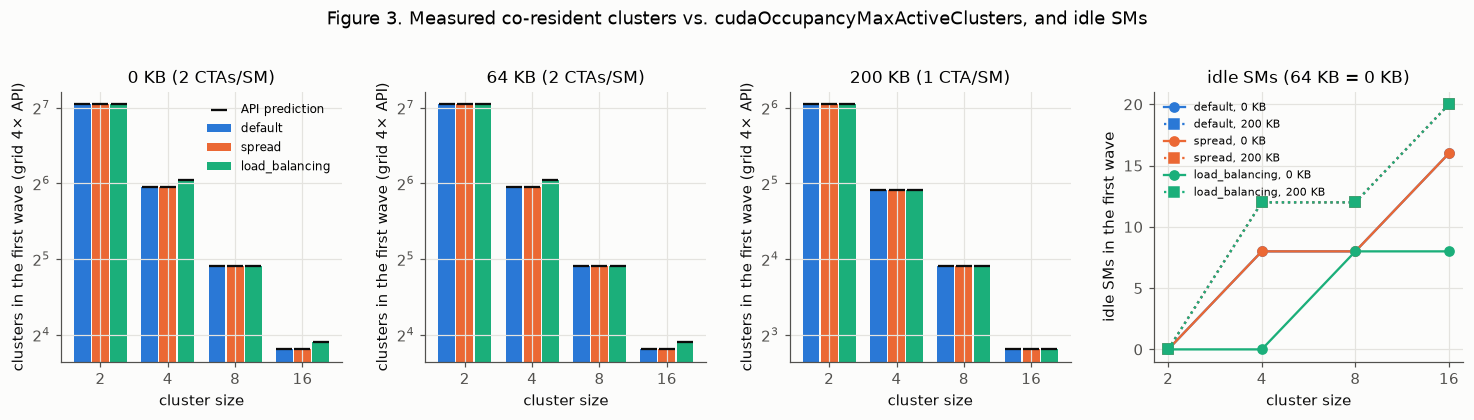

**Per configuration: API prediction, first-wave clusters (min/max over 5 repetitions), idle SMs; grid 1× and 4× the API**

policy        default                                                        \
                  api      first_wave_max      first_wave_min      sms_idle   
grid_mult           1    4              1    4              1    4        1   
smem_bytes cs                                                                 
0          2      132  132            132  132            132  132        0   
           4       62   62             62   62             62   62        8   
           8       30   30             30   30             30   30        8   
           16      14   14             14   14             14   14       16   
65536      2      132  132            132  132            132  132        0   
           4       62   62             62   62             62   62        8   
           8       30   30             30   30             30   30        8   
           16      14   14             14   14             14   14       16   
204800     2       66   66             66   66             66   66        0   
           4       30   30             30   30             30   30       12   
           8       15   15             15   15             15   15       12   
           16       7    7              7    7              7    7       20   

policy            load_balancing                                               \
                             api      first_wave_max      first_wave_min        
grid_mult       4              1    4              1    4              1    4   
smem_bytes cs                                                                   
0          2    0            132  132            132  132            132  132   
           4    8             66   66             66   66             66   66   
           8    8             30   30             30   30             30   30   
           16  16             15   15             15   15             15   15   
65536      2    0            132  132            132  132            132  132   
           4    8             66   66             66   66             66   66   
           8    8             30   30             30   30             30   30   
           16  16             15   15             15   15             15   15   
204800     2    0             66   66             66   66             66   66   
           4   12             30   30             30   30             30   30   
           8   12             15   15             15   15             15   15   
           16  20              7    7              7    7              7    7   

policy                     spread                                          \
              sms_idle        api      first_wave_max      first_wave_min   
grid_mult            1   4      1    4              1    4              1   
smem_bytes cs                                                               
0          2         0   0    132  132            132  132            132   
           4         0   0     62   62             62   62             62   
           8         8   8     30   30             30   30             30   
           16        8   8     14   14             14   14             14   
65536      2         0   0    132  132            132  132            132   
           4         0   0     62   62             62   62             62   
           8         8   8     30   30             30   30             30   
           16        8   8     14   14             14   14             14   
204800     2         0   0     66   66             66   66             66   
           4        12  12     30   30             30   30             30   
           8        12  12     15   15             15   15             15   
           16       20  20      7    7              7    7              7   

policy                           
                   sms_idle      
grid_mult        4        1   4  
smem_bytes cs                    
0          2   132        0   0  
           4    62        8   8  
 

In [6]:
o = occ.groupby(["smem_bytes", "cs", "policy", "grid_mult"]).agg(
    api=("api_max_active_clusters", "first"), first_wave_min=("measured_first_wave_clusters", "min"),
    first_wave_max=("measured_first_wave_clusters", "max"), sms_idle=("sms_idle", "median"),
    max_ctas_per_sm=("max_ctas_per_sm", "max"), colocated_clusters_max=("clusters_colocated", "max"))
fig, axs = plt.subplots(1, 4, figsize=(13.5, 3.7), gridspec_kw={"width_ratios": [1, 1, 1, 1.1]})
POL = ["default", "spread", "load_balancing"]
for ax, smem in zip(axs[:3], [0, 65536, 204800]):
    x = np.arange(4)
    for j, pol in enumerate(POL):
        sub = o.xs((smem, pol), level=("smem_bytes", "policy")).xs(4, level="grid_mult")
        ax.bar(x + (j - 1) * 0.27, sub.first_wave_max.values, 0.25, color=PAL[j], label=pol)
        ax.scatter(x + (j - 1) * 0.27, sub.api.values, marker="_", s=120, color=INK, zorder=3, label="API prediction" if j == 0 else None)
    ax.set_xticks(x, ["2", "4", "8", "16"]); ax.set_xlabel("cluster size"); ax.set_yscale("log", base=2)
    ax.set_title(f"{SMEM[smem]}"); ax.set_ylabel("clusters in the first wave (grid 4× API)")
axs[0].legend(frameon=False, fontsize=8)
for j, pol in enumerate(POL):
    for k, smem in enumerate([0, 204800]):
        sub = o.xs((smem, pol), level=("smem_bytes", "policy")).xs(1, level="grid_mult")
        axs[3].plot([2, 4, 8, 16], sub.sms_idle.values, marker="os"[k], color=PAL[j], ls="-:"[k], lw=1.5,
                    label=f"{pol}, {SMEM[smem].split(' (')[0]}")
axs[3].set_xscale("log", base=2); axs[3].set_xticks([2, 4, 8, 16], ["2", "4", "8", "16"]); axs[3].set_xlabel("cluster size")
axs[3].set_ylabel("idle SMs in the first wave"); axs[3].set_title("idle SMs (64 KB = 0 KB)"); axs[3].legend(frameon=False, fontsize=7)
fig.suptitle("Figure 3. Measured co-resident clusters vs. cudaOccupancyMaxActiveClusters, and idle SMs", y=1.02)
fig.tight_layout(); plt.show()
ot = o.reset_index()
ot = ot.pivot_table(index=["smem_bytes", "cs"], columns=["policy", "grid_mult"],
                    values=["api", "first_wave_min", "first_wave_max", "sms_idle"], aggfunc="first")
ot = ot.reorder_levels([1, 0, 2], axis=1).sort_index(axis=1)
pd.set_option("display.max_columns", 40)
display(Markdown("**Per configuration: API prediction, first-wave clusters (min/max over 5 repetitions), idle SMs; grid 1× and 4× the API**"))
display(ot.astype(int))

### Which SMs host which clusters: GPCs and the 4 TPCs that only take clusters of 2

All CTAs of a cluster share one GPC, so SMs that ever appear in the same cluster belong to the same GPC. Joining every pair of SMs that shared a cluster of ≥ 4 CTAs in any of the 1 470 recorded launches gives the components below. The SM clock groups from the timer experiment (SMs whose clock under the lock differs by < 0.1 MHz in every launch) are shown for comparison; they are read from that experiment's own measurement files.

In [7]:
p = pd.read_csv(F + "placement.csv", usecols=["run_id", "launch_idx", "cs", "policy", "grid_blocks", "smem_bytes", "rep", "block_idx",
                                               "cluster_id", "rank", "smid", "t_start_ns", "t_end_ns", "probe"])
p = p[p.run_id.isin([rid_k1, rid_k2])]
print(f"placement rows: {len(p)} (K1 {int((p.probe == 'k1_overhead').sum())}, K2 {int((p.probe == 'k2_occupancy').sum())}) "
      f"from {p.groupby(['run_id', 'launch_idx']).ngroups} launches")

def components(df, min_cs):
    par = list(range(132))
    def f(x):
        while par[x] != x: par[x] = par[par[x]]; x = par[x]
        return x
    for s in df[df.cs >= min_cs].groupby(["run_id", "launch_idx", "cluster_id"]).smid.agg(list):
        for x in s[1:]: par[f(x)] = f(s[0])
    return pd.Series([f(i) for i in range(132)], index=range(132))

comp4 = components(p, 4)
comp2 = components(p, 2)
sizes4 = comp4.value_counts()
big_ids = sizes4[sizes4 > 2].index
print("components from clusters of ≥ 4:", sorted(sizes4[sizes4 > 2].values, reverse=True),
      "+ SMs never in a cluster of ≥ 4:", sorted(comp4[~comp4.isin(big_ids)].index.tolist()))
print("pairs those SMs form in clusters of 2:", sorted(comp2[~comp4.isin(big_ids)].groupby(comp2).apply(lambda s: tuple(s.index)).tolist()))

# SM clock groups from the timer experiment (all 132 SMs measuring at once)
try:
    T = "../01__timers_and_harness/results/"
    gr, r01 = pd.read_csv(T + "01__timers__globaltimer_resolution.csv"), pd.read_csv(T + "01__timers_and_harness__runs.csv")
    rid = r01[r01.cmdline.str.contains("k2all", na=False) & (r01.status == "complete")].run_id.max()
    a = gr[(gr.run_id == rid) & (gr.kind == "window_total")]
    P = a.pivot_table(index="smid", columns="launch_idx", values="sm_mhz_from_globaltimer")
    D = np.abs(P.values[:, None, :] - P.values[None, :, :]).max(axis=2)
    lab = -np.ones(len(P), int); g = 0
    for i in range(len(P)):
        if lab[i] >= 0: continue
        st, lab[i] = [i], g
        while st:
            j = st.pop()
            for k in np.where((D[j] < 0.1) & (lab < 0))[0]: lab[k] = g; st.append(k)
        g += 1
    clk = pd.Series(lab, index=P.index)
except FileNotFoundError:
    clk = None

placement rows: 584830 (K1 400530, K2 184300) from 1470 launches


components from clusters of ≥ 4: [np.int64(18), np.int64(18), np.int64(16), np.int64(16), np.int64(16), np.int64(16), np.int64(16), np.int64(8)] + SMs never in a cluster of ≥ 4: [124, 125, 126, 127, 128, 129, 130, 131]
pairs those SMs form in clusters of 2: [(124, 125), (126, 127), (128, 129), (130, 131)]


In [8]:
# GPC candidates: each component of clusters >= 4, plus the leftover TPCs assigned to the clock group they share SMs with
big_rank = {cid: i for i, cid in enumerate(sorted(big_ids, key=lambda cid: comp4[comp4 == cid].index.min()))}
gpc = comp4.map(big_rank)
if clk is not None:
    clk_to_gpc = pd.Series({cg: gpc[clk[clk == cg].index].dropna().mode().iloc[0] for cg in clk.unique()})
    gpc = gpc.fillna(clk.map(clk_to_gpc))
gpc = gpc.astype("Int64")
lonely = sorted(comp4[~comp4.isin(big_ids)].index)
rows = []
for gid in sorted(gpc.dropna().unique()):
    sms = gpc[gpc == gid].index
    cap = [s for s in sms if s not in lonely]
    rows.append({"GPC": f"G{gid}", "SMs": len(sms), "SMs in clusters of ≥ 4": len(cap),
                 "SMs only in clusters of ≤ 2": " ".join(map(str, [s for s in sms if s in lonely])) or "—",
                 "clock group size (timer experiment)": (clk[sms].nunique() == 1 and (clk == clk[sms[0]]).sum()) if clk is not None else None,
                 "%smid": " ".join(map(str, sms))})
gt = pd.DataFrame(rows).set_index("GPC")
display(gt)
if clk is not None:
    display(Markdown("**Cross-tabulation: SM groups from cluster co-membership (rows) vs. clock groups (columns)**"))
    display(pd.crosstab(gpc.astype(str).values, clk.reindex(range(132)).values, rownames=["GPC candidate"], colnames=["clock group"]))

# clusters per GPC in the first wave of each K2 configuration (Default, 1x, repetition 0)
k2 = p[(p.probe == "k2_occupancy") & (p.policy == "default") & (p.rep == 0)]
k2 = k2[k2.grid_blocks == k2.groupby(["smem_bytes", "cs"]).grid_blocks.transform("min")]
per = k2.assign(g=k2.smid.map(gpc)).groupby(["smem_bytes", "cs", "cluster_id"]).g.agg(lambda s: s.iloc[0] if s.nunique() == 1 else -1)
pg = per.groupby(["smem_bytes", "cs"]).value_counts().unstack(fill_value=0)
pg.columns = [f"G{c}" if c >= 0 else "spans GPCs" for c in pg.columns]
display(Markdown("**Clusters per GPC candidate (first wave, Default)**")); display(pg)

,SMs,SMs in clusters of ≥ 4,SMs only in clusters of ≤ 2,clock group size (timer experiment),%smid
GPC,,,,,
G0,12,8,124 125 130 131,12,0 1 16 17 32 33 48 49 124 125 130 131
G1,16,16,—,16,2 3 18 19 34 35 50 51 64 65 78 79 92 93 106 107
G2,16,16,—,16,4 5 20 21 36 37 52 53 66 67 80 81 94 95 108 109
G3,16,16,—,16,6 7 22 23 38 39 54 55 68 69 82 83 96 97 110 111
G4,18,16,126 127,18,8 9 24 25 40 41 56 57 70 71 84 85 98 99 112 11...
G5,18,16,128 129,18,10 11 26 27 42 43 58 59 72 73 86 87 100 101 11...
G6,18,18,—,18,12 13 28 29 44 45 60 61 74 75 88 89 102 103 11...
G7,18,18,—,18,14 15 30 31 46 47 62 63 76 77 90 91 104 105 11...


**Cross-tabulation: SM groups from cluster co-membership (rows) vs. clock groups (columns)**

clock group,0,1,2,3,4,5,6,7
GPC candidate,,,,,,,,
0,12,0,0,0,0,0,0,0
1,0,16,0,0,0,0,0,0
2,0,0,16,0,0,0,0,0
3,0,0,0,16,0,0,0,0
4,0,0,0,0,18,0,0,0
5,0,0,0,0,0,18,0,0
6,0,0,0,0,0,0,18,0
7,0,0,0,0,0,0,0,18


**Clusters per GPC candidate (first wave, Default)**

G0  G1  G2  G3  G4  G5  G6  G7
smem_bytes cs                                
0          2   12  16  16  16  18  18  18  18
           4    4   8   8   8   8   8   9   9
           8    2   4   4   4   4   4   4   4
           16   0   2   2   2   2   2   2   2
65536      2   12  16  16  16  18  18  18  18
           4    4   8   8   8   8   8   9   9
           8    2   4   4   4   4   4   4   4
           16   0   2   2   2   2   2   2   2
204800     2    6   8   8   8   9   9   9   9
           4    2   4   4   4   4   4   4   4
           8    1   2   2   2   2   2   2   2
           16   0   1   1   1   1   1   1   1

The cluster co-membership splits the GPU into eight groups of 18, 18, 16, 16, 16, 16, 16 and 8 SMs, plus four TPCs (SMs 124–131) that never share a cluster of 4 or more with any other SM. Each of those TPCs sits in a clock group with one of the eight groups (two of them with the 8-SM group, one each with two 16-SM groups), which turns the eight groups into the clock groups of 18, 18, 18, 18, 16, 16, 16 and 12 SMs. Nsight Compute counts the same eight GPC instances (table further below). The eight clock groups are therefore the GPCs, with 66 TPCs distributed 9/9/9/9/8/8/8/6. Within three of these GPCs, one or two TPCs (62–65) only ever host clusters of 2 (or, under LoadBalancing with 2 CTAs/SM, a whole cluster of 4 on one TPC). This accounts for the cluster counts exactly: with 1 CTA/SM the 12-SM GPC fits two clusters of 4 (not three) and one of 8, the 18-SM GPCs with an excluded TPC fit one cluster of 16 on their other 16 SMs, and the 30 clusters of 4 that the API reports (rather than 31) follow.

`%smid` numbering interleaves the GPCs: the two SMs of a TPC have consecutive ids `2t, 2t+1`, and consecutive TPCs of one GPC are 16 ids apart (14 after the 8-SM group has run out of TPCs).

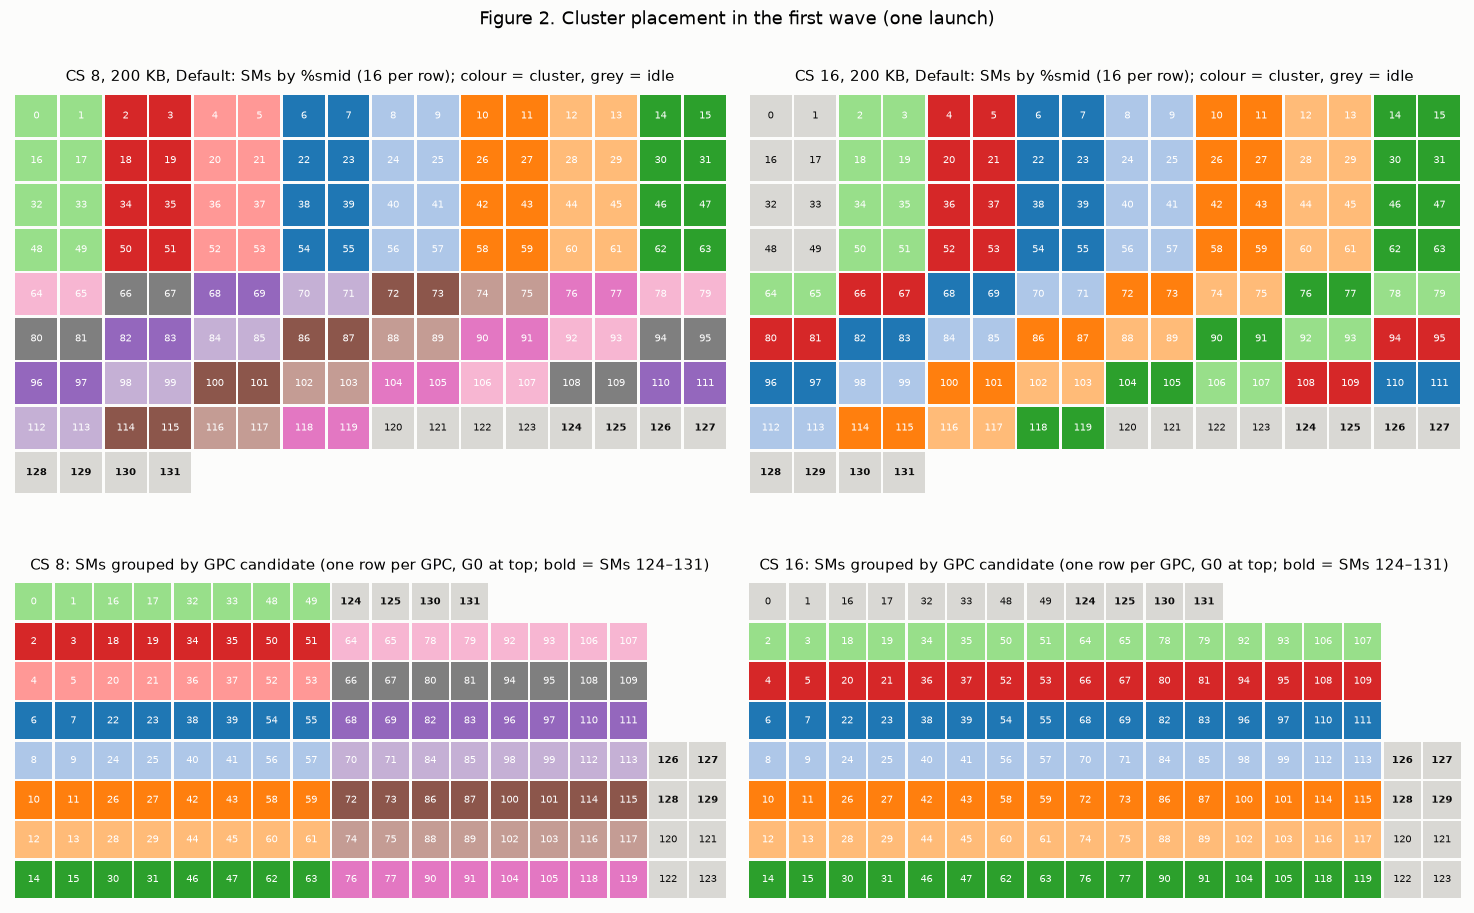

In [9]:
def tile(ax, smids_order, colors, labels, ncol, title, lonely_set):
    n = len(smids_order)
    for k, sm in enumerate(smids_order):
        if sm is None: continue
        r, cc = divmod(k, ncol)
        ax.add_patch(plt.Rectangle((cc, -r), 0.94, 0.94, color=colors.get(sm, "#d9d8d4"), lw=0))
        ax.text(cc + 0.47, -r + 0.47, str(sm), ha="center", va="center", fontsize=6.5,
                color=INK if sm not in colors else "white", fontweight="bold" if sm in lonely_set else None)
    rows = (n + ncol - 1) // ncol
    ax.set_xlim(-0.1, ncol); ax.set_ylim(-rows + 0.9, 1.05); ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title, fontsize=10)

cmap = plt.get_cmap("tab20")
fig, axs = plt.subplots(2, 2, figsize=(13.5, 9.2), gridspec_kw={"height_ratios": [1, 1.1]})
for j, cs in enumerate([8, 16]):
    g = k2[(k2.smem_bytes == 204800) & (k2.cs == cs)]
    cid = dict(zip(g.smid, g.cluster_id))
    colors = {sm: cmap(c % 20) for sm, c in cid.items()}
    tile(axs[0, j], list(range(132)), colors, cid, 16, f"CS {cs}, 200 KB, Default: SMs by %smid (16 per row); colour = cluster, grey = idle", set(lonely))
    order = []
    for gid in sorted(gpc.dropna().unique()):
        sms = sorted(gpc[gpc == gid].index); order += sms + [None] * (18 - len(sms))
    tile(axs[1, j], order, colors, cid, 18, f"CS {cs}: SMs grouped by GPC candidate (one row per GPC, G0 at top; bold = SMs 124–131)", set(lonely))
fig.suptitle("Figure 2. Cluster placement in the first wave (one launch)", y=0.995)
fig.tight_layout(); plt.show()

### Placement invariants

(i) CTAs of one cluster on distinct SMs under Default and Spread; (ii) how often LoadBalancing co-locates CTAs of one cluster; (iii) whether repeating a launch puts each cluster rank on the same SM as the previous launch. (iii) is evaluated on the five consecutive K2 repetitions, and separately on K1, whose repetitions of a configuration are interleaved with launches of the other cluster sizes.

In [10]:
def per_cluster(df):
    return df.groupby(["run_id", "launch_idx", "cluster_id"]).smid.agg(lambda s: s.nunique() < len(s))
cl = p[p.cs >= 2].copy()
coloc = cl.groupby(["probe", "policy", "smem_bytes"]).apply(lambda d: pd.Series({
    "clusters": d.groupby(["run_id", "launch_idx", "cluster_id"]).ngroups, "co-located": int(per_cluster(d).sum())}))
coloc["fraction co-located"] = coloc["co-located"] / coloc["clusters"]
display(Markdown("**(i), (ii): clusters with ≥ 2 CTAs on one SM**")); display(coloc)
lb = occ[occ.policy == "load_balancing"].groupby(["smem_bytes", "cs", "grid_mult"]).clusters_colocated.median()
display(Markdown("LoadBalancing, co-located clusters per launch (median):")); display(lb.unstack("grid_mult"))

def stability(df, keys):
    out = []
    for key, g in df.groupby(keys):
        t = g.pivot_table(index=["cluster_id", "rank"], columns="rep", values="smid")
        fr = [(t[r] == t[r - 1]).groupby(level=0).all().mean() for r in range(1, t.shape[1])]
        out.append(dict(zip(keys, key)) | {"fraction of clusters with identical rank→SM tuple (mean)": np.mean(fr), "min": np.min(fr)})
    return pd.DataFrame(out)
s2 = stability(p[p.probe == "k2_occupancy"], ["smem_bytes", "cs", "policy", "grid_blocks"])
s2["waves"] = s2.groupby(["smem_bytes", "cs", "policy"]).grid_blocks.rank().map({1.0: "1 (grid = API)", 2.0: "4 (grid = 4× API)"})
display(Markdown("**(iii) K2, consecutive repetitions**"))
display(s2.groupby(["waves", "policy"])["fraction of clusters with identical rank→SM tuple (mean)"].agg(["mean", "min", "max"]).round(3))
s1 = stability(p[(p.probe == "k1_overhead") & (p.cs >= 2)], ["smem_bytes", "cs", "grid_blocks"])
display(Markdown("**(iii) K1, interleaved repetitions (all grids)**"))
display(s1.groupby("cs")["fraction of clusters with identical rank→SM tuple (mean)"].describe(percentiles=[0.5])[["mean", "min", "50%", "max"]].round(3))

# rank pairs and TPCs, split into first-wave clusters (started on an idle GPU) and clusters of later waves
key = ["run_id", "launch_idx", "cluster_id"]
cl["launch_min_end"] = cl.groupby(["run_id", "launch_idx"]).t_end_ns.transform("min")
info = cl.groupby(key).agg(cs=("cs", "first"), start=("t_start_ns", "max"), min_end=("launch_min_end", "first"),
                           coloc=("smid", lambda s: s.nunique() < len(s)))
info["wave"] = np.where(info.start < info.min_end, "first wave", "later waves")
w2 = cl.pivot_table(index=key, columns="rank", values="smid")
pairs = []
for cs in [2, 4, 8, 16]:
    for wave in ["first wave", "later waves"]:
        idx = info[(info.cs == cs) & (info.wave == wave) & ~info.coloc].index
        sub = w2.loc[idx]
        ok = np.all([(sub[2 * k] // 2 == sub[2 * k + 1] // 2) for k in range(cs // 2)], axis=0)
        pairs.append({"cluster size": cs, "wave": wave, "clusters": len(sub), "fraction with ranks (2k, 2k+1) on one TPC": ok.mean()})
display(Markdown("**Ranks 2k and 2k+1 on one TPC (SMs 2t, 2t+1)?** (clusters without co-location)"))
display(pd.DataFrame(pairs).set_index(["cluster size", "wave"]).round(3))

**(i), (ii): clusters with ≥ 2 CTAs on one SM**

clusters  co-located  \
probe        policy         smem_bytes                         
k1_overhead  default        0              20375           0   
                            65536          20375           0   
                            204800         20375           0   
k2_occupancy default        0               5950           0   
                            65536           5950           0   
                            204800          2950           0   
             load_balancing 0               6075         373   
                            65536           6075         391   
                            204800          2950           0   
             spread         0               5950           0   
                            65536           5950           0   
                            204800          2950           0   

                                        fraction co-located  
probe        policy         smem_bytes                       
k1_overhead  default        0                         0.000  
                            65536                     0.000  
                            204800                    0.000  
k2_occupancy default        0                         0.000  
                            65536                     0.000  
                            204800                    0.000  
             load_balancing 0                         0.061  
                            65536                     0.064  
                            204800                    0.000  
             spread         0                         0.000  
                            65536                     0.000  
                            204800                    0.000

LoadBalancing, co-located clusters per launch (median):

grid_mult        1     4
smem_bytes cs           
0          2   0.0   0.0
           4   4.0  18.0
           8   0.0  15.0
           16  1.0  34.0
65536      2   0.0   0.0
           4   4.0  17.0
           8   0.0  14.0
           16  1.0  42.0
204800     2   0.0   0.0
           4   0.0   0.0
           8   0.0   0.0
           16  0.0   0.0

**(iii) K2, consecutive repetitions**

mean    min    max
waves             policy                             
1 (grid = API)    default         1.000  1.000  1.000
                  load_balancing  1.000  1.000  1.000
                  spread          1.000  1.000  1.000
4 (grid = 4× API) default         0.529  0.333  0.812
                  load_balancing  0.440  0.284  0.859
                  spread          0.487  0.321  0.804

**(iii) K1, interleaved repetitions (all grids)**

,mean,min,50%,max
cs,,,,
2,0.716,0.174,0.875,1.0
4,0.783,0.075,1.000,1.0
8,0.720,0.053,1.000,1.0
16,0.844,0.326,1.000,1.0


**Ranks 2k and 2k+1 on one TPC (SMs 2t, 2t+1)?** (clusters without co-location)

clusters  fraction with ranks (2k, 2k+1) on one TPC
cluster size wave                                                            
2            first wave      19365                                      1.000
             later waves     37950                                      0.836
4            first wave       9115                                      1.000
             later waves     18709                                      0.798
8            first wave       4470                                      1.000
             later waves      9167                                      0.745
16           first wave       2125                                      1.000
             later waves      4260                                      0.975

### Nsight Compute launch statistics

In [11]:
n = pd.read_csv(F + "ncu_launch.csv")
cols = {"launch__cluster_max_active": "max active clusters (ncu)", "launch__cluster_scheduling_policy": "policy reported by ncu",
        "gpc__cgas_launched.sum": "clusters launched", "gpc__cgas_launched.min": "per GPC min", "gpc__cgas_launched.max": "per GPC max",
        "gpc__cgas_launched.avg": "per GPC avg", "sm__cycles_elapsed.avg.per_second": "SM clock (Hz)", "gpu__time_duration.sum": "duration (ns)"}
nt = n[["probe", "cs", "policy", "smem_bytes", "grid_blocks"] + list(cols)].rename(columns=cols)
nt["GPC instances (sum / avg)"] = (nt["clusters launched"] / nt["per GPC avg"]).round(2)
api = occ.groupby(["cs", "policy", "smem_bytes"]).api_max_active_clusters.first()
nt["API max active clusters"] = [api.get((c, pol, s), np.nan) if pr == "k2_occupancy" else np.nan
                                 for pr, c, pol, s in zip(nt.probe, nt.cs, nt.policy, nt.smem_bytes)]
display(nt)
print(f"SM clock during profiling: {nt['SM clock (Hz)'].min() / 1e6:.1f}–{nt['SM clock (Hz)'].max() / 1e6:.1f} MHz")

,probe,cs,policy,smem_bytes,grid_blocks,max active clusters (ncu),policy reported by ncu,clusters launched,per GPC min,per GPC max,per GPC avg,SM clock (Hz),duration (ns),GPC instances (sum / avg),API max active clusters
0,k2_occupancy,2,default,0,264,132 (132),PolicySpread,132,12,18,16.50,1.632e+09,1229632,8.00,132.0
1,k2_occupancy,2,spread,0,264,132 (132),PolicySpread,132,12,18,16.50,1.627e+09,1235744,8.00,132.0
2,k2_occupancy,2,load_balancing,0,264,132 (132),PolicyLoadBalancing,132,12,18,16.50,1.632e+09,1228480,8.00,132.0
3,k2_occupancy,4,default,0,248,62 (62),PolicySpread,62,4,9,7.75,1.632e+09,1228800,8.00,62.0
4,k2_occupancy,4,spread,0,248,62 (62),PolicySpread,62,4,9,7.75,1.628e+09,1234976,8.00,62.0
5,k2_occupancy,4,load_balancing,0,264,66 (66),PolicyLoadBalancing,66,6,9,8.25,1.626e+09,1236320,8.00,66.0
6,k2_occupancy,8,default,0,240,30 (30),PolicySpread,30,2,4,3.75,1.632e+09,1228992,8.00,30.0
7,k2_occupancy,8,spread,0,240,30 (30),PolicySpread,30,2,4,3.75,1.628e+09,1235264,8.00,30.0
8,k2_occupancy,8,load_balancing,0,240,30 (30),PolicyLoadBalancing,30,2,4,3.75,1.628e+09,1235296,8.00,30.0
9,k2_occupancy,16,default,0,224,14 (14),PolicySpread,14,0,2,1.75,1.632e+09,1228704,8.00,14.0


SM clock during profiling: 1625.9–1632.8 MHz


## Insights

- **Cluster launch overhead on this H100 is entirely wave quantisation caused by idle SMs.** Every wave takes the same time with or without clusters (≈ 62–64 µs for a 61 µs CTA), the empty-kernel launch costs the same 4.2–4.3 µs for every cluster size, and back-to-back kernels are separated by ≈ 1.06 µs without clusters and ≈ 1.12–1.15 µs with clusters (≈ 0.1 µs more). A grid pays only when the cluster form needs more waves than the plain form: +12 % at 2112 CTAs for clusters of 4 and 8, +19 % (1 CTA/SM) to +24 % (2 CTAs/SM) for clusters of 16, and up to +90 % for grids just above one cluster wave. Clusters of 1 and 2 cost nothing measurable.
- **Capacity per cluster size** (1 CTA/SM): 66 clusters of 2 (132 SMs), 30 of 4 and 15 of 8 (120 SMs), 7 of 16 (112 SMs). With 2 CTAs/SM: 132, 62, 30 and 14 clusters under Default/Spread. `cudaOccupancyMaxActiveClusters` and ncu's `launch__cluster_max_active` match the measured first wave in every launch, so the API can be used to size grids exactly on this device.
- **GPC structure.** Cluster co-membership, the per-SM clock groups and ncu's eight GPC instances agree on eight GPCs of 18, 18, 18, 18, 16, 16, 16 and 12 SMs. Only one GPC lacks 16 cluster-capable SMs, so at most 7 clusters of 16 run at once, and every experiment with clusters of 16 runs on 112 SMs.
- **Four TPCs (SMs 124–131) are restricted to clusters of 2.** They belong to the 12-SM GPC (two TPCs) and to two 18-SM GPCs (one each), yet in 1 470 launches they never shared a cluster of ≥ 4 with any other SM, even with 4× oversubscription. The hardware (and the occupancy API) treats them as unable to join larger clusters; why is not visible from these measurements. For later experiments it means that clusters of ≥ 4 never include SMs 124–131, and that the cluster-capable part of the GPU has GPCs of 18, 18, 16, 16, 16, 16, 16 and 8 SMs.
- **Placement is structured and repeatable on an idle GPU.** In the first wave, ranks 2k and 2k+1 of every cluster share a TPC and consecutive rank pairs take consecutive TPCs of one GPC; clusters of later waves take whichever SMs of a GPC have just been freed, so their rank pairs often straddle TPCs. Default and Spread never put two CTAs of a cluster on one SM (ncu reports the Default policy as Spread). When the grid fits in one wave, every rank lands on the same SM in every repetition; with several waves 28–86 % of clusters keep their SMs from one launch to the next. Experiments that bin by SM must therefore read `%smid` per launch, and experiments that need a fixed rank→SM map should launch at most one wave of clusters.
- **LoadBalancing** differs from the other two policies only when 2 CTAs fit on an SM: it then co-locates CTAs of one cluster (about 6 % of its clusters) to fill SMs: 66 instead of 62 clusters of 4 (all 132 SMs busy) and 15 instead of 14 clusters of 16. Accesses to "remote" shared memory within such a cluster can be SM-local. With 1 CTA/SM all three policies place clusters identically.
- **Limitations.** Overhead is measured with one event pair per launch, so small grids carry ≈ ±1 µs of host jitter (±2 % at one wave); the time per wave and the nsys trace isolate the device-side cost. The SM grouping into GPCs is inferred from co-scheduling and clock behaviour, not read from hardware registers.